
Loading Dataset...

Dataset Shape: (2240, 28)

First Five Records
      ID  Year_Birth   Education Marital_Status       Income  Kidhome  \
0   1826        1970  Graduation       Divorced  $84,835.00         0   
1      1        1961  Graduation         Single  $57,091.00         0   
2  10476        1958  Graduation        Married  $67,267.00         0   
3   1386        1967  Graduation       Together  $32,474.00         1   
4   5371        1989  Graduation         Single  $21,474.00         1   

   Teenhome Dt_Customer  Recency  MntWines  MntFruits  MntMeatProducts  \
0         0     6/16/14        0       189        104              379   
1         0     6/15/14        0       464          5               64   
2         1     5/13/14        0       134         11               59   
3         1     5/11/14        0        10          0                1   
4         0      4/8/14        0         6         16               24   

   MntFishProducts  MntSweetProducts  MntGoldProd

/tmp/ipykernel_1126/3466759433.py:58: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])
/tmp/ipykernel_1126/3466759433.py:102: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Income"].fillna(


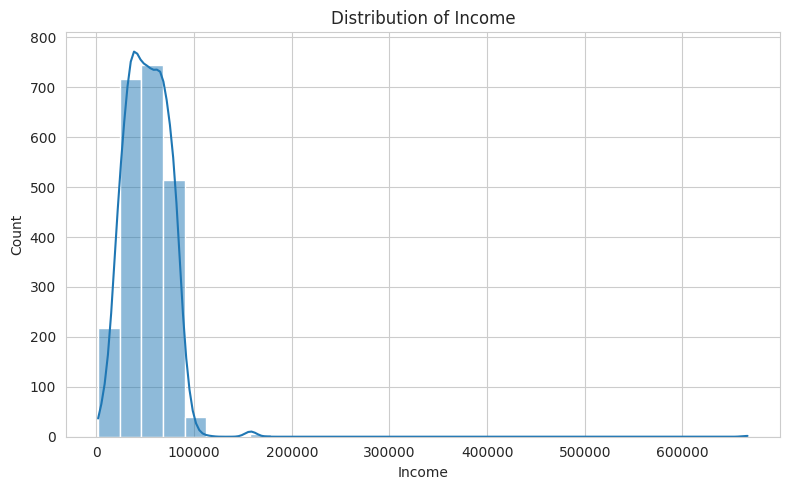

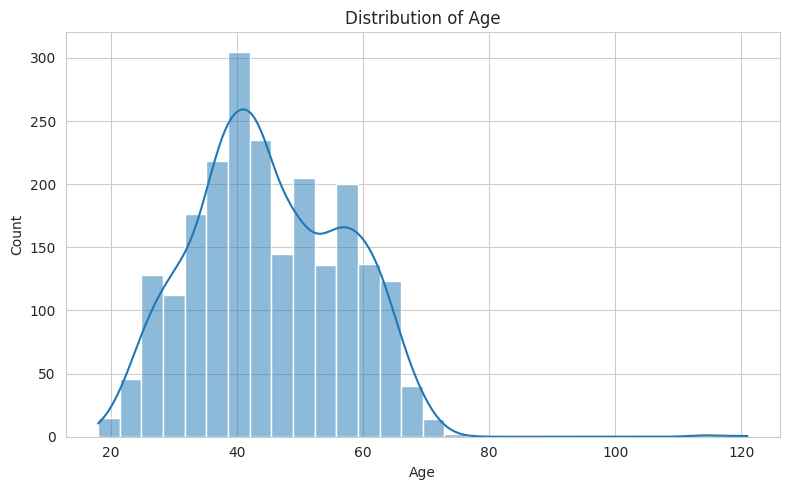

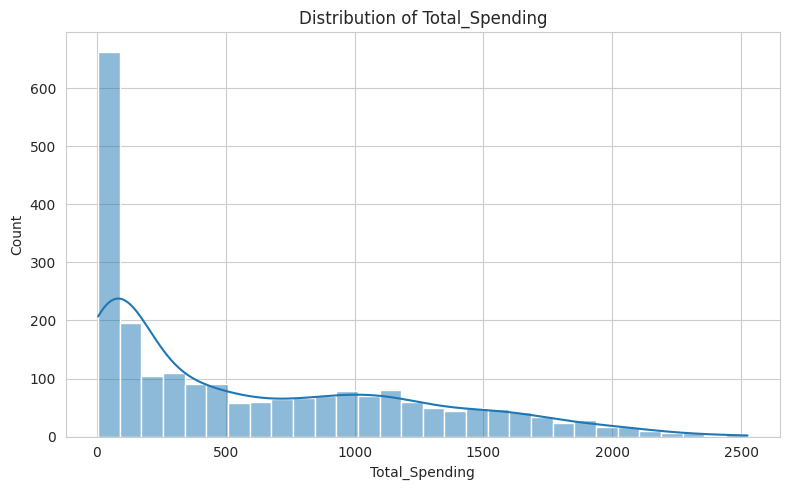

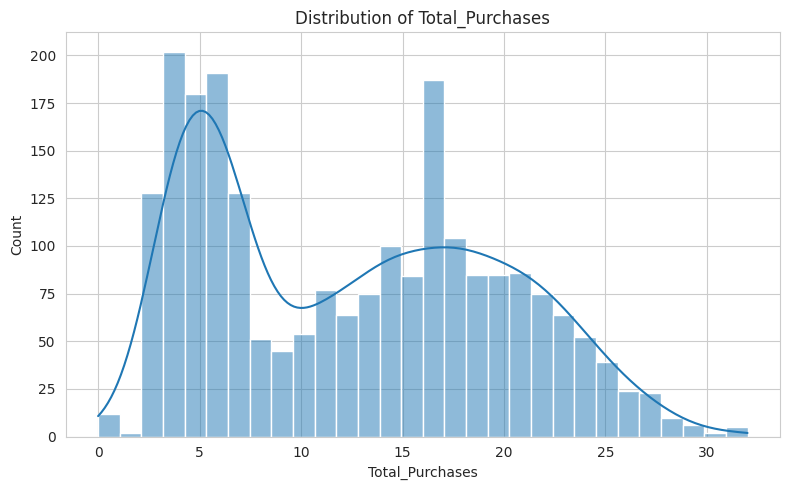


Generating Boxplots...


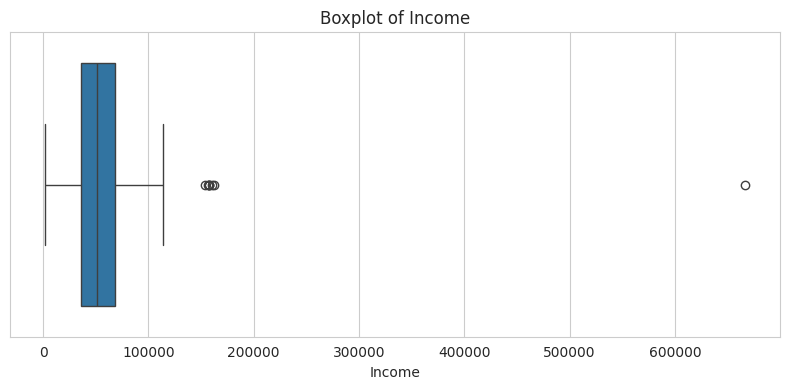

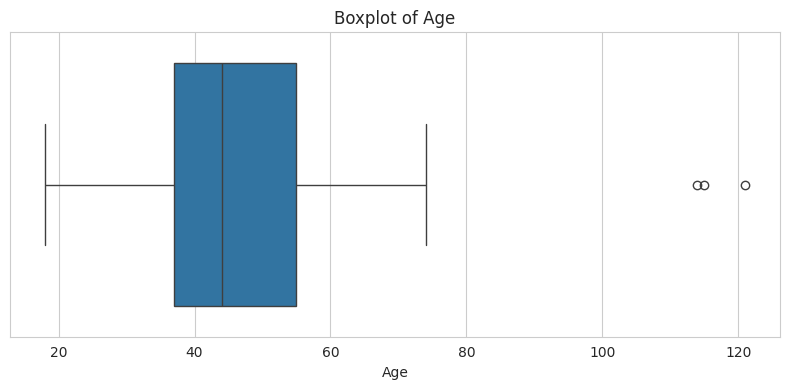

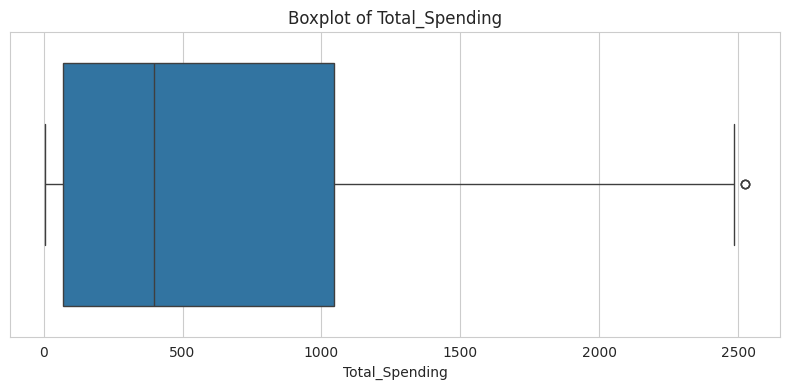

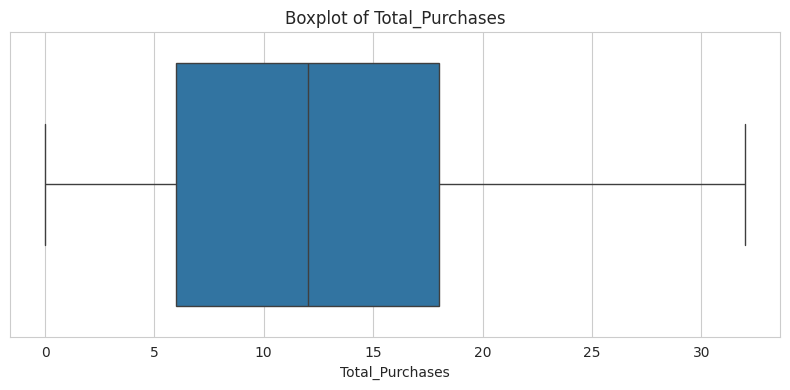


Treating Outliers using IQR Method...

Performing Ordinal Encoding...

Performing One-Hot Encoding...

Generating Correlation Heatmap...


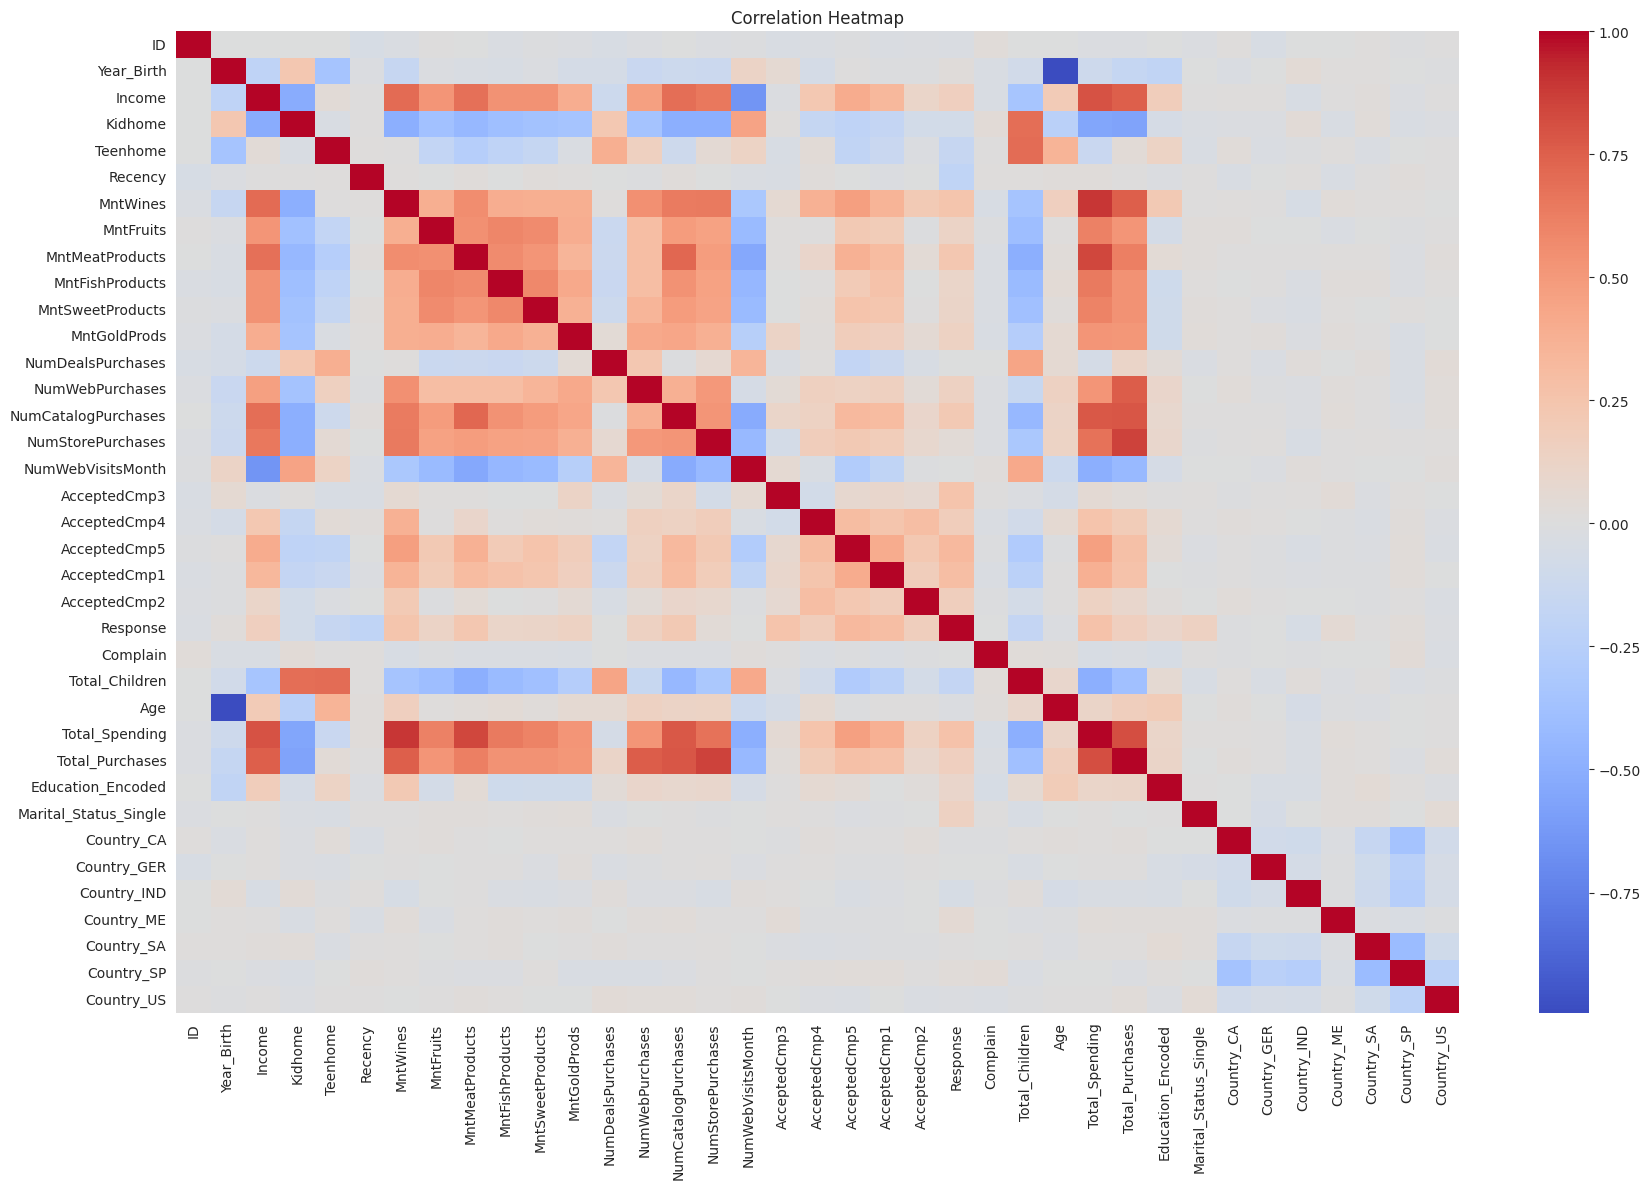


Hypothesis A
Correlation : 0.1676
P-value : 1.3870345756497308e-15
Reject H0

Hypothesis B
Correlation : -0.1855
P-value : 8.821613870728844e-19
Reject H0

Hypothesis C
                     NumStorePurchases  NumWebPurchases  NumCatalogPurchases
NumStorePurchases             1.000000         0.502713             0.518738
NumWebPurchases               0.502713         1.000000             0.378376
NumCatalogPurchases           0.518738         0.378376             1.000000


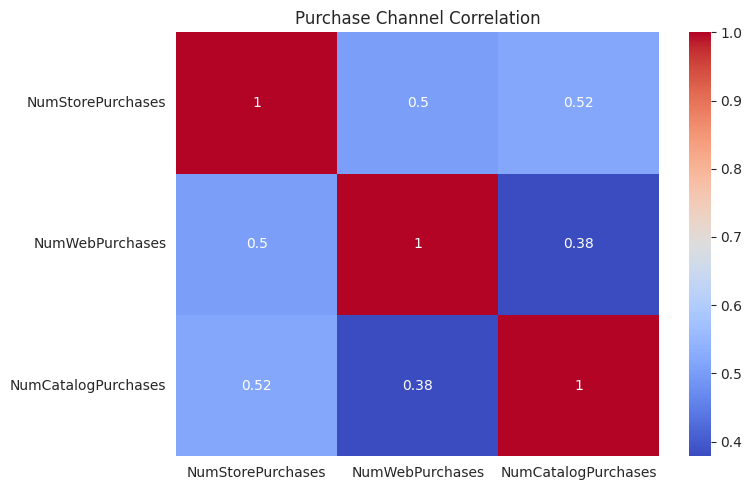


Hypothesis D
T Statistic : 1.4682
P-value : 0.1446759042957516
Fail to Reject H0

Product Revenue Analysis
  Product  Revenue
0    Wine   680816
2    Meat   373968
5    Gold    98609
3    Fish    84057
4  Sweets    60621
1  Fruits    58917


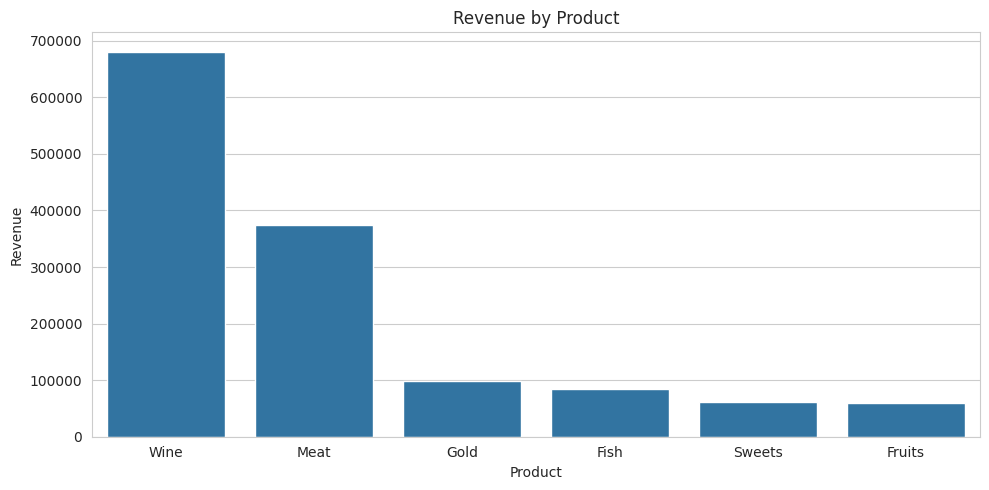

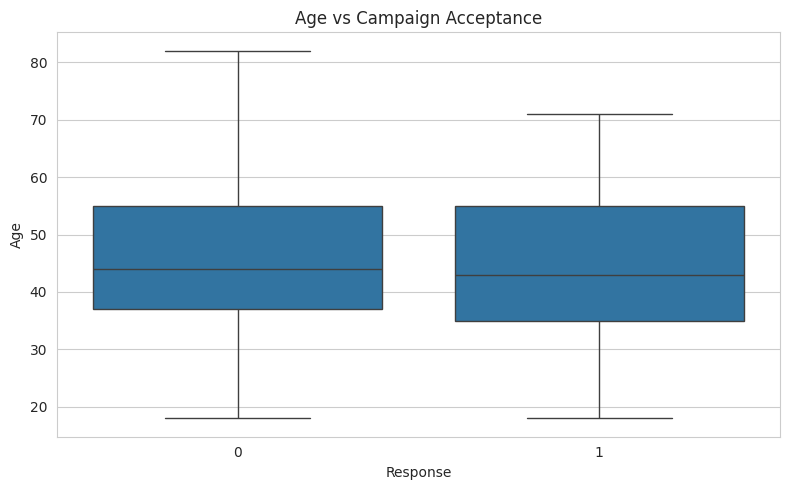

  Country  Accepted_Customers
6      SP                 176
5      SA                  52
1      CA                  38
0     AUS                  23
2     GER                  17
3     IND                  13
7      US                  13
4      ME                   2


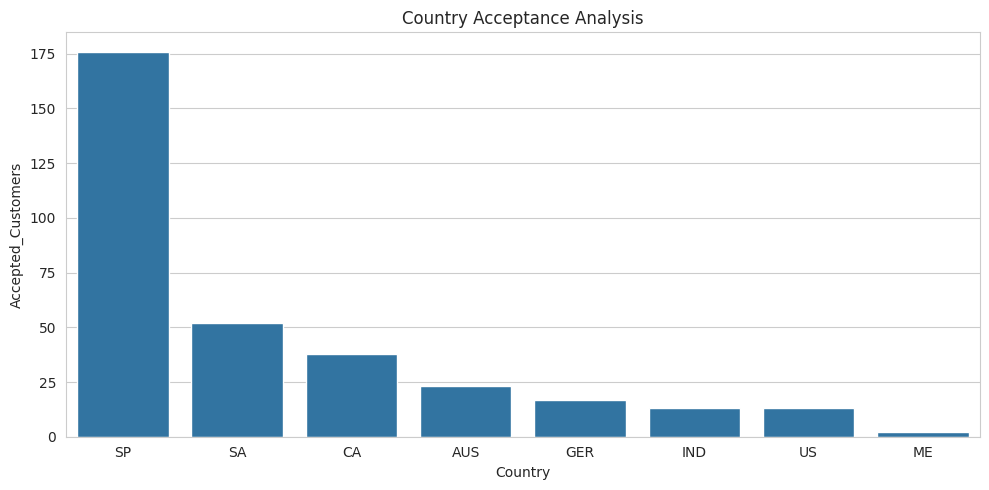

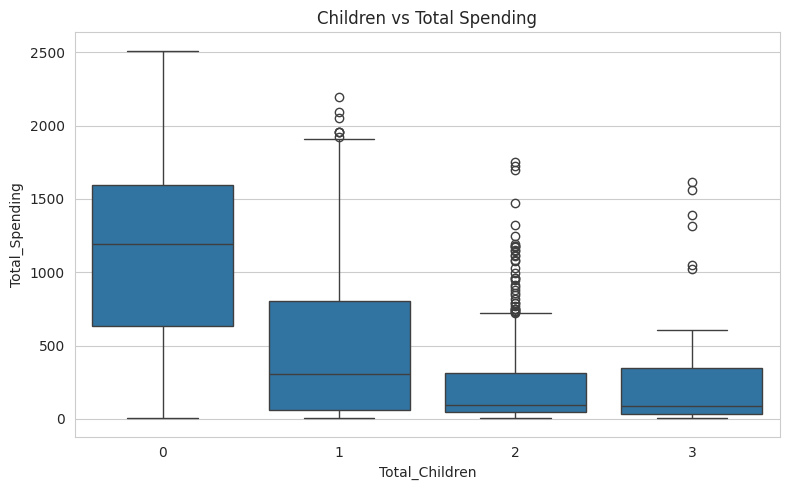

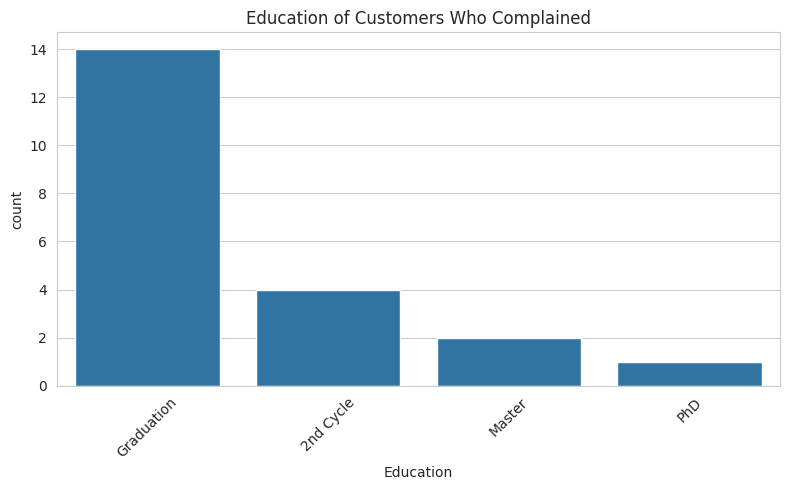


Project Summary
                Metric     Value
0  Number of Customers   2240.00
1       Average Income  51870.87
2          Average Age     45.15
3     Average Spending    605.78
4    Average Purchases     12.54
5  Acceptance Rate (%)     14.91

Cleaned dataset exported successfully.
Project completed successfully.


In [10]:
# =============================================================================
# APPLIED DATA SCIENCE WITH PYTHON
# COURSE END PROJECT
# MARKETING CAMPAIGNS ANALYSIS
# =============================================================================

# =============================================================================
# 1. IMPORT LIBRARIES
# =============================================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from scipy.stats import ttest_ind

sns.set_style("whitegrid")

pd.set_option('display.max_columns', None)

# =============================================================================
# 2. LOAD DATASET
# =============================================================================

print("\nLoading Dataset...\n")

df = pd.read_csv("/content/marketing_data.csv")

# Strip leading/trailing whitespaces from column names to fix ' KeyError: Income'
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

print("\nFirst Five Records")
print(df.head())

# =============================================================================
# 3. DATA INSPECTION
# =============================================================================

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

# =============================================================================
# 4. DATA CLEANING
# =============================================================================

print("\nPerforming Data Cleaning...")

# Convert customer date

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])

# Clean income column

df["Income"] = (
    df["Income"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Income"] = pd.to_numeric(df["Income"], errors="coerce")

# Education cleanup

df["Education"] = df["Education"].replace({
    "2n Cycle": "2nd Cycle"
})

# Marital Status cleanup

df["Marital_Status"] = df["Marital_Status"].replace({
    "Married": "Partnered",
    "Together": "Partnered",
    "Single": "Single",
    "Divorced": "Single",
    "Widow": "Single",
    "Alone": "Single",
    "YOLO": "Single",
    "Absurd": "Single"
})

# =============================================================================
# 5. MISSING VALUE IMPUTATION
# =============================================================================

print("\nImputing Missing Income Values...")

df["Income"] = df.groupby(
    ["Education", "Marital_Status"]
)["Income"].transform(
    lambda x: x.fillna(x.median())
)

df["Income"].fillna(
    df["Income"].median(),
    inplace=True
)

print("Remaining Missing Income Values:",
      df["Income"].isnull().sum())

# =============================================================================
# 6. FEATURE ENGINEERING
# =============================================================================

print("\nCreating New Features...")

# Total Children

df["Total_Children"] = (
    df["Kidhome"] +
    df["Teenhome"]
)

# Age

df["Age"] = 2014 - df["Year_Birth"]

# Total Spending

df["Total_Spending"] = (
      df["MntWines"]
    + df["MntFruits"]
    + df["MntMeatProducts"]
    + df["MntFishProducts"]
    + df["MntSweetProducts"]
    + df["MntGoldProds"]
)

# Total Purchases

df["Total_Purchases"] = (
      df["NumWebPurchases"]
    + df["NumCatalogPurchases"]
    + df["NumStorePurchases"]
)

# =============================================================================
# 7. HISTOGRAMS
# =============================================================================

print("\nGenerating Histograms...")

eda_columns = [
    "Income",
    "Age",
    "Total_Spending",
    "Total_Purchases"
]

for col in eda_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[col],
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")

    plt.tight_layout()
    plt.show()

# =============================================================================
# 8. BOXPLOTS
# =============================================================================

print("\nGenerating Boxplots...")

for col in eda_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[col]
    )

    plt.title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

# =============================================================================
# 9. OUTLIER TREATMENT
# =============================================================================

print("\nTreating Outliers using IQR Method...")

def treat_outliers(data, column):

    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    data[column] = np.where(
        data[column] < lower,
        lower,
        np.where(
            data[column] > upper,
            upper,
            data[column]
        )
    )

    return data

for col in ["Income", "Age", "Total_Spending"]:
    df = treat_outliers(df, col)

# =============================================================================
# 10. ORDINAL ENCODING
# =============================================================================

print("\nPerforming Ordinal Encoding...")

education_map = {
    "Basic": 1,
    "2nd Cycle": 2,
    "Graduation": 3,
    "Master": 4,
    "PhD": 5
}

df["Education_Encoded"] = (
    df["Education"]
    .map(education_map)
)

# =============================================================================
# 11. ONE-HOT ENCODING
# =============================================================================

print("\nPerforming One-Hot Encoding...")

df_encoded = pd.get_dummies(
    df,
    columns=["Marital_Status", "Country"],
    drop_first=True
)

# =============================================================================
# 12. CORRELATION HEATMAP
# =============================================================================

print("\nGenerating Correlation Heatmap...")

plt.figure(figsize=(18, 12))

corr_matrix = df_encoded.corr(
   numeric_only=True
)

sns.heatmap(
    corr_matrix,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

# =============================================================================
# 13. HYPOTHESIS A
# OLDER PEOPLE PREFER STORES
# =============================================================================

print("\nHypothesis A")

corr, pvalue = spearmanr(
    df["Age"],
    df["NumStorePurchases"]
)

print("Correlation :", round(corr, 4))
print("P-value :", pvalue)

if pvalue < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

# =============================================================================
# 14. HYPOTHESIS B
# CHILDREN AND ONLINE SHOPPING
# =============================================================================

print("\nHypothesis B")

corr, pvalue = spearmanr(
    df["Total_Children"],
    df["NumWebPurchases"]
)

print("Correlation :", round(corr, 4))
print("P-value :", pvalue)

if pvalue < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

# =============================================================================
# 15. HYPOTHESIS C
# CHANNEL CANNIBALIZATION
# =============================================================================

print("\nHypothesis C")

channel_corr = df[
    [
        "NumStorePurchases",
        "NumWebPurchases",
        "NumCatalogPurchases"
    ]
].corr()

print(channel_corr)

plt.figure(figsize=(8, 5))

sns.heatmap(
    channel_corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Purchase Channel Correlation")

plt.tight_layout()
plt.show()

# =============================================================================
# 16. HYPOTHESIS D
# USA VS REST OF WORLD
# =============================================================================

print("\nHypothesis D")

usa = df[df["Country"] == "US"]
rest_world = df[df["Country"] != "US"]

t_stat, pvalue = ttest_ind(
    usa["Total_Purchases"],
    rest_world["Total_Purchases"],
    equal_var=False
)

print("T Statistic :", round(t_stat, 4))
print("P-value :", pvalue)

if pvalue < 0.05:
    print("Reject H0")
    print("USA significantly differs from Rest of World")
else:
    print("Fail to Reject H0")

# =============================================================================
# 17. TOP AND LOWEST REVENUE PRODUCTS
# =============================================================================

print("\nProduct Revenue Analysis")

product_sales = pd.DataFrame({

    "Product": [
        "Wine",
        "Fruits",
        "Meat",
        "Fish",
        "Sweets",
        "Gold"
    ],

    "Revenue": [
        df["MntWines"].sum(),
        df["MntFruits"].sum(),
        df["MntMeatProducts"].sum(),
        df["MntFishProducts"].sum(),
        df["MntSweetProducts"].sum(),
        df["MntGoldProds"].sum()
    ]
})

product_sales.sort_values(
    by="Revenue",
    ascending=False,
    inplace=True
)

print(product_sales)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=product_sales,
    x="Product",
    y="Revenue"
)

plt.title("Revenue by Product")

plt.tight_layout()
plt.show()

# =============================================================================
# 18. AGE VS LAST CAMPAIGN ACCEPTANCE
# =============================================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Response",
    y="Age"
)

plt.title("Age vs Campaign Acceptance")

plt.tight_layout()
plt.show()

# =============================================================================
# 19. COUNTRY WITH HIGHEST ACCEPTANCE
# =============================================================================

country_acceptance = (
    df[df["Response"] == 1]
    .groupby("Country")
    .size()
    .reset_index(name="Accepted_Customers")
    .sort_values(
        by="Accepted_Customers",
        ascending=False
    )
)

print(country_acceptance)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=country_acceptance,
    x="Country",
    y="Accepted_Customers"
)

plt.title("Country Acceptance Analysis")

plt.tight_layout()
plt.show()

# =============================================================================
# 20. CHILDREN VS TOTAL SPENDING
# =============================================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Total_Children",
    y="Total_Spending"
)

plt.title("Children vs Total Spending")

plt.tight_layout()
plt.show()

# =============================================================================
# 21. EDUCATION OF COMPLAINING CUSTOMERS
# =============================================================================

complaints = df[df["Complain"] == 1]

plt.figure(figsize=(8, 5))

sns.countplot(
    data=complaints,
    x="Education",
    order=complaints["Education"]
    .value_counts()
    .index
)

plt.title("Education of Customers Who Complained")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# =============================================================================
# 22. PROJECT SUMMARY
# =============================================================================

summary = pd.DataFrame({

    "Metric": [
        "Number of Customers",
        "Average Income",
        "Average Age",
        "Average Spending",
        "Average Purchases",
        "Acceptance Rate (%)"
    ],

    "Value": [
        len(df),
        round(df["Income"].mean(), 2),
        round(df["Age"].mean(), 2),
        round(df["Total_Spending"].mean(), 2),
        round(df["Total_Purchases"].mean(), 2),
        round(df["Response"].mean() * 100, 2)
    ]
})

print("\nProject Summary")
print(summary)

# =============================================================================
# 23. EXPORT CLEANED DATASET
# =============================================================================

df.to_csv(
    "marketing_campaign_cleaned.csv",
    index=False
)

print("\nCleaned dataset exported successfully.")
print("Project completed successfully.")

In [6]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-2.5-flash', 'google/gemini-2.5…